In [ ]:
# Ô 1: Import các thư viện cần thiết

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

# Cấu hình hiển thị biểu đồ
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.unicode_minus"] = False

print("Đã import thành công các thư viện cần thiết.")

   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.6 MB 433.6 kB/s eta 0:00:28
   - -------------------------------------- 0.5/12.6 MB 433.6 kB/s eta 0:00:28
   -- ------------------------------------- 0.8/12.6 MB 446.2 kB/s eta 0:00:27
   -- ------------------------------------- 0.8/12.6 MB 446.2 kB/s eta 0:00:27
   -- ------------------------------------- 0.8/12.6 MB 446.2 kB/s eta 0:00:27
   --- ------------------------------------ 1

ERROR: Could not install packages due to an OSError: [Errno 28] No space left on device


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


ModuleNotFoundError: No module named 'numpy'

In [ ]:
# Ô 2: Tạo dữ liệu AirPassengers
# 144 quan sát theo tháng từ 01/1949 đến 12/1960

air_values = [
    112,118,132,129,121,135,148,148,136,119,104,118,
    115,126,141,135,125,149,170,170,158,133,114,140,
    145,150,178,163,172,178,199,199,184,162,146,166,
    171,180,193,181,183,218,230,242,209,191,172,194,
    196,196,236,235,229,243,264,272,237,211,180,201,
    204,188,235,227,234,264,302,293,259,229,203,229,
    242,233,267,269,270,315,364,347,312,274,237,278,
    284,277,317,313,318,374,413,405,355,306,271,306,
    315,301,356,348,355,422,465,467,404,347,305,336,
    340,318,362,348,363,435,491,505,404,359,310,337,
    360,342,406,396,420,472,548,559,463,407,362,405,
    417,391,419,461,472,535,622,606,508,461,390,432
]

# Tạo mốc thời gian đầu mỗi tháng
dates = pd.date_range(
    start="1949-01-01",
    periods=len(air_values),
    freq="MS"
)

# Tạo chuỗi thời gian
air_passengers = pd.Series(
    air_values,
    index=dates,
    name="AirPassengers"
)

print("Đã tạo dữ liệu AirPassengers thành công.")
print("Số lượng quan sát:", len(air_passengers))
print("Tháng bắt đầu:", air_passengers.index[0].strftime("%Y-%m"))
print("Tháng kết thúc:", air_passengers.index[-1].strftime("%Y-%m"))
print("Tần suất:", air_passengers.index.freqstr)

Đã tạo dữ liệu AirPassengers thành công.
Số lượng quan sát: 144
Tháng bắt đầu: 1949-01
Tháng kết thúc: 1960-12
Tần suất: MS


In [ ]:
# Ô 3: Xem trước và kiểm tra dữ liệu

# Tạo bảng dữ liệu gồm thời gian và số hành khách
df = pd.DataFrame({
    "Month": air_passengers.index,
    "Passengers": air_passengers.values
})

print("1. Năm quan sát đầu tiên:")
display(df.head())

print("\n2. Thông tin dữ liệu:")
df.info()

print("\n3. Thống kê mô tả:")
display(df["Passengers"].describe().to_frame())

print("\n4. Kiểm tra dữ liệu thiếu:")
print(df.isna().sum())

print("\n5. Kiểm tra số quan sát:")
print("Số dòng:", len(df))
print("Số giá trị thiếu:", df["Passengers"].isna().sum())

1. Năm quan sát đầu tiên:


,Month,Passengers
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121



2. Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Month       144 non-null    datetime64[ns]
 1   Passengers  144 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.4 KB

3. Thống kê mô tả:


,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000



4. Kiểm tra dữ liệu thiếu:
Month         0
Passengers    0
dtype: int64

5. Kiểm tra số quan sát:
Số dòng: 144
Số giá trị thiếu: 0


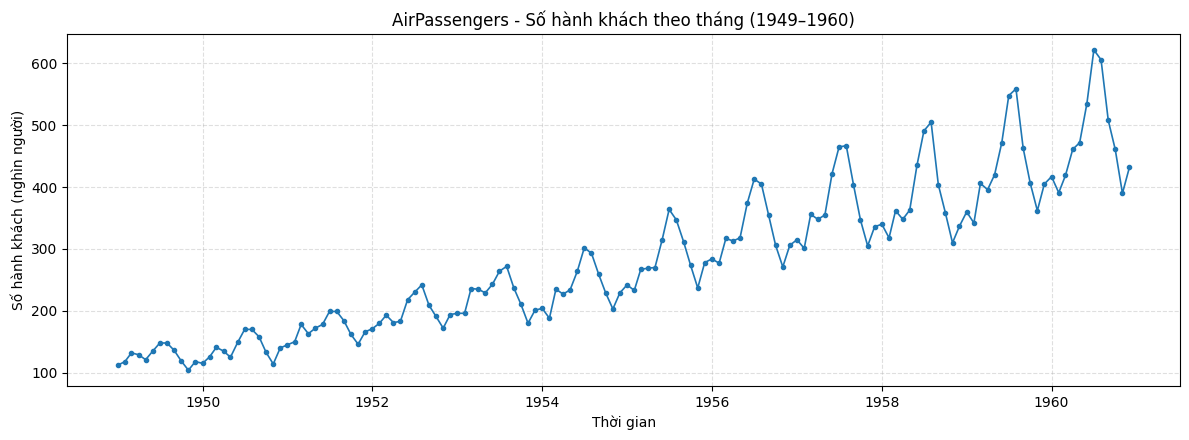

In [ ]:
# Ô 4: Vẽ chuỗi thời gian AirPassengers

plt.figure(figsize=(12, 4.5))

plt.plot(
    air_passengers.index,
    air_passengers.values,
    marker="o",
    markersize=3,
    linewidth=1.2
)

plt.title("AirPassengers - Số hành khách theo tháng (1949–1960)")
plt.xlabel("Thời gian")
plt.ylabel("Số hành khách (nghìn người)")
plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

<Figure size 1000x450 with 0 Axes>

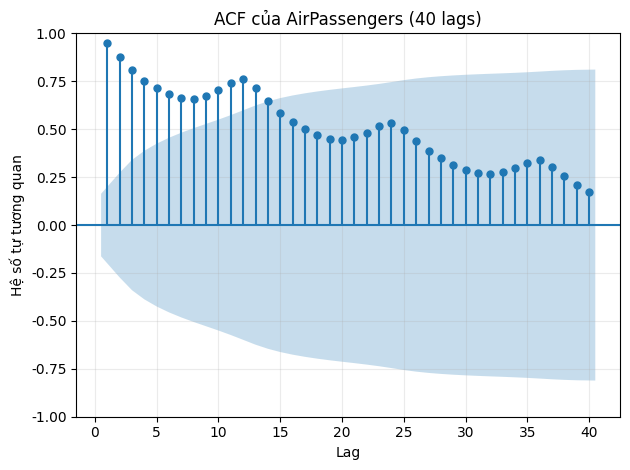

Giới hạn tham khảo 95%: ±0.163
ACF tại một số độ trễ:
Lag  1: ACF = 0.9480
Lag  2: ACF = 0.8756
Lag  3: ACF = 0.8067
Lag  6: ACF = 0.6817
Lag 12: ACF = 0.7604
Lag 24: ACF = 0.5322
Lag 36: ACF = 0.3370


In [ ]:
# Ô 5: Tính và vẽ ACF đến 40 lags

acf_values = acf(
    air_passengers,
    nlags=40,
    fft=False
)

plt.figure(figsize=(10, 4.5))

plot_acf(
    air_passengers,
    lags=40,
    alpha=0.05,
    zero=False
)

plt.title("ACF của AirPassengers (40 lags)")
plt.xlabel("Lag")
plt.ylabel("Hệ số tự tương quan")
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

# Giới hạn tin cậy 95% tham khảo
ci_limit = 1.96 / np.sqrt(len(air_passengers))

print(f"Giới hạn tham khảo 95%: ±{ci_limit:.3f}")
print("ACF tại một số độ trễ:")
for lag in [1, 2, 3, 6, 12, 24, 36]:
    print(f"Lag {lag:2d}: ACF = {acf_values[lag]:.4f}")

<Figure size 1000x450 with 0 Axes>

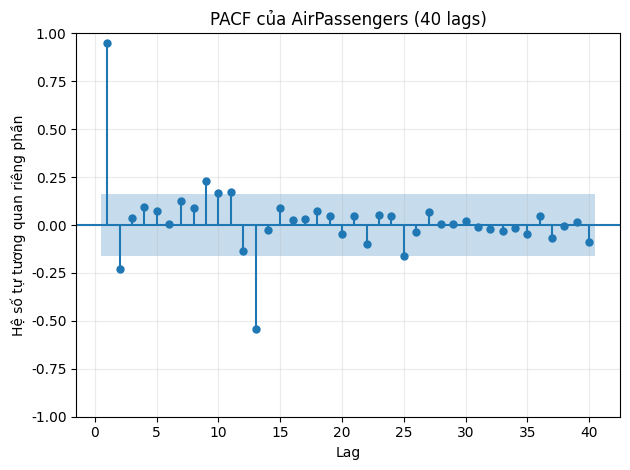

PACF tại một số độ trễ:
Lag  1: PACF = 0.9480
Lag  2: PACF = -0.2294
Lag  3: PACF = 0.0381
Lag  6: PACF = 0.0077
Lag 12: PACF = -0.1354
Lag 24: PACF = 0.0480
Lag 36: PACF = 0.0462


In [ ]:
# Ô 6: Tính và vẽ PACF đến 40 lags

pacf_values = pacf(
    air_passengers,
    nlags=40,
    method="ywm"
)

plt.figure(figsize=(10, 4.5))

plot_pacf(
    air_passengers,
    lags=40,
    alpha=0.05,
    method="ywm",
    zero=False
)

plt.title("PACF của AirPassengers (40 lags)")
plt.xlabel("Lag")
plt.ylabel("Hệ số tự tương quan riêng phần")
plt.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

print("PACF tại một số độ trễ:")
for lag in [1, 2, 3, 6, 12, 24, 36]:
    print(f"Lag {lag:2d}: PACF = {pacf_values[lag]:.4f}")

In [ ]:
# Ô 7: Bảng giá trị ACF và PACF từ lag 1 đến lag 40

result = pd.DataFrame({
    "Lag": range(1, 41),
    "ACF": acf_values[1:41],
    "PACF": pacf_values[1:41]
})

print("Bảng ACF/PACF:")
display(result.round(4))

# Các độ trễ có hệ số ACF/PACF lớn nhất theo trị tuyệt đối
top_acf = result.loc[
    result["ACF"].abs().sort_values(ascending=False).index
].head(5)

top_pacf = result.loc[
    result["PACF"].abs().sort_values(ascending=False).index
].head(5)

print("5 lag có |ACF| lớn nhất:")
display(top_acf.round(4))

print("5 lag có |PACF| lớn nhất:")
display(top_pacf.round(4))

Bảng ACF/PACF:


,Lag,ACF,PACF
0,1,0.9480,0.9480
1,2,0.8756,-0.2294
2,3,0.8067,0.0381
3,4,0.7526,0.0938
4,5,0.7138,0.0736
5,6,0.6817,0.0077
6,7,0.6629,0.1256
7,8,0.6556,0.0900
8,9,0.6709,0.2325
9,10,0.7027,0.1661


5 lag có |ACF| lớn nhất:


,Lag,ACF,PACF
0,1,0.9480,0.9480
1,2,0.8756,-0.2294
2,3,0.8067,0.0381
11,12,0.7604,-0.1354
3,4,0.7526,0.0938


5 lag có |PACF| lớn nhất:


,Lag,ACF,PACF
0,1,0.9480,0.9480
12,13,0.7127,-0.5397
8,9,0.6709,0.2325
1,2,0.8756,-0.2294
10,11,0.7432,0.1713


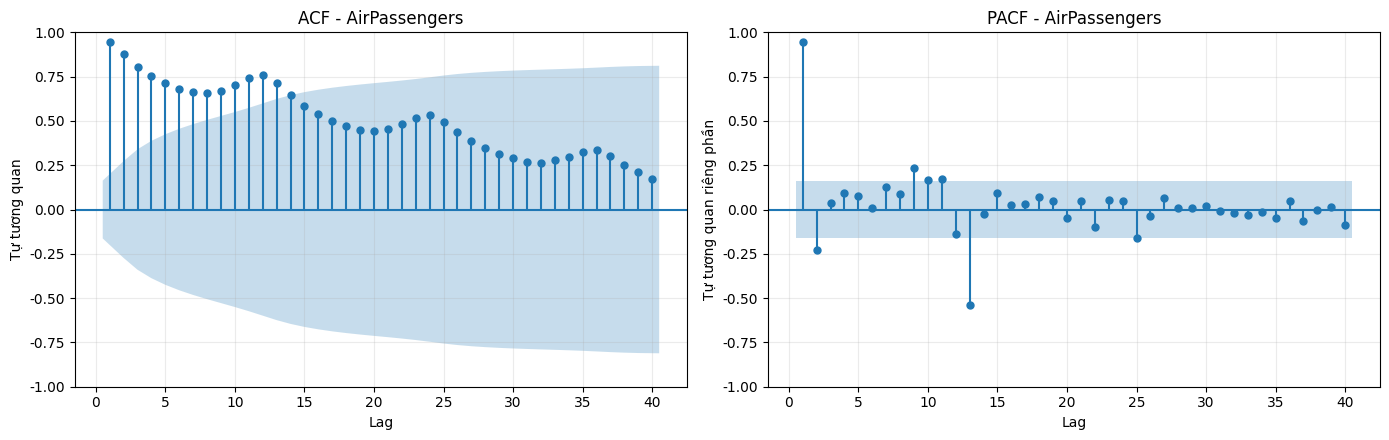

In [ ]:
# Ô 8: Vẽ ACF và PACF cạnh nhau

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

plot_acf(
    air_passengers,
    lags=40,
    alpha=0.05,
    zero=False,
    ax=axes[0]
)
axes[0].set_title("ACF - AirPassengers")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Tự tương quan")
axes[0].grid(True, alpha=0.25)

plot_pacf(
    air_passengers,
    lags=40,
    alpha=0.05,
    method="ywm",
    zero=False,
    ax=axes[1]
)
axes[1].set_title("PACF - AirPassengers")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Tự tương quan riêng phần")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

## BÀI TẬP 1: TÍNH VÀ PHÂN TÍCH ACF/PACF

**1. Mô tả dữ liệu**

Bộ dữ liệu AirPassengers gồm 144 quan sát theo tháng, từ tháng 01/1949 đến tháng 12/1960. Dữ liệu phản ánh số hành khách hàng không quốc tế theo thời gian. Biểu đồ chuỗi gốc cho thấy lượng hành khách có xu hướng tăng và xuất hiện các biến động lặp lại theo mùa.

**2. Phân tích ACF**

Biểu đồ ACF cho thấy hệ số tự tương quan ở các độ trễ đầu có giá trị dương lớn và giảm tương đối chậm. Một số độ trễ theo chu kỳ 12 tháng cũng thể hiện tương quan đáng kể. Điều này cho thấy các quan sát trong chuỗi có sự phụ thuộc theo thời gian, đồng thời có dấu hiệu mùa vụ hằng năm.

**3. Phân tích PACF**

Biểu đồ PACF cho biết mức tương quan riêng phần tại từng độ trễ sau khi xét ảnh hưởng của các độ trễ trung gian. Các cột vượt khoảng tin cậy 95% là những độ trễ cần được chú ý. Cần kết hợp bảng giá trị PACF với hình dạng biểu đồ để nhận diện các độ trễ nổi bật.

**4. Kết luận chung**

AirPassengers không phải là chuỗi White Noise thuần túy vì dữ liệu có xu hướng tăng, dấu hiệu mùa vụ và tự tương quan rõ rệt. ACF giúp nhận diện cấu trúc tương quan theo thời gian, trong khi PACF hỗ trợ phân tích mối tương quan riêng phần. Kết quả này bổ sung cho Bài tập 2 về White Noise và Bài tập 3 về phân rã chuỗi thời gian.

Để xác định độ trễ quan trọng nhất, cần đối chiếu các giá trị ACF/PACF tính được và các cột vượt giới hạn tin cậy 95%, thay vì chỉ dựa vào một độ trễ riêng lẻ.